# IndicAgriRAG: data, model, and evaluation

This notebook runs the project’s evidence-grounded agricultural QA workflow and reports **Accuracy, Precision, Recall, F1-score, confusion matrix**, and additional retrieval, reference-overlap, latency, and human-review metrics when their required labels are available.

**Data:** ICAR Kharif Agro-Advisories for Farmers 2025 PDFs in `data/raw/`.

**Models:** `intfloat/multilingual-e5-base` for multilingual dense retrieval, combined with BM25; Ollama `qwen2.5:7b` for answer generation. This project does not fine-tune a model.

**Evaluation caution:** this notebook scores all 600 rows using the current gold labels, including 500 provisional auto-labels (400 corpus-generated questions and 100 Hinglish variants). Treat the metrics as diagnostic, not human-validated research results, until the generated questions and evidence labels are reviewed. Reference answers are noisy and are not ground truth.


## 1. Install and configure

Run this notebook from the `IndicAgriRAG` project directory. Install `requirements.txt` and the local package first (`pip install -r requirements.txt` and `pip install -e .`). For generation, install/start Ollama and pull `qwen2.5:7b`. The embedding model downloads from Hugging Face on first use.

If needed, set `OLLAMA_URL` and `OLLAMA_MODEL` in your environment before starting Jupyter. GPU is optional; CPU embedding can take longer.


In [1]:
from pathlib import Path
import json, os, sys, time, re
import numpy as np
import pandas as pd
from IPython.display import display, Image
from indic_agri_rag.config import ROOT, RAW_DIR, INDEX_DIR, OUTPUT_DIR, EMBED_MODEL

ROOT = Path(ROOT)
QUESTIONS_CSV = ROOT / "data" / "benchmark" / "questions.csv"
GOLD_CSV = ROOT / "evaluation" / "gold.csv"
PREDICTIONS_CSV = ROOT / "outputs" / "predictions.csv"
REVIEW_CSV = ROOT / "evaluation" / "answer_review.csv"
TOP_K = 5
GENERATION_MODEL = os.getenv("OLLAMA_MODEL", "qwen2.5:7b")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Project: {ROOT.name}")
print(f"Evidence PDFs found: {len(list(RAW_DIR.rglob('*.pdf')))}")
print(f"Embedding model: {EMBED_MODEL}")
print(f"Answer model: {GENERATION_MODEL}")


Project: IndicAgriRAG-updated
Evidence PDFs found: 2
Embedding model: BAAI/bge-m3
Answer model: qwen2.5:7b


## 2. Prepare the ICAR evidence dataset

Extract page text and make overlapping chunks while preserving source filename and page number for citations. These PDF chunks are the only evidence used to answer questions. The benchmark reference answers are never indexed.


In [2]:
from indic_agri_rag.corpus import build_corpus

if not list(RAW_DIR.rglob("*.pdf")):
    raise FileNotFoundError(f"Add the supplied ICAR PDF files under {RAW_DIR}")
chunks = build_corpus()
print(f"Indexed {len(chunks):,} evidence chunks across {len({c['source'] for c in chunks})} PDF(s).")


d:\ANIKET\COLLAGE\5th SEM\(3) CSET346 - (NLP) Natural Language Processing\NLP Project -\Working prototypes\IndicAgriRAG-updated\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Indexed 2,137 evidence chunks across 2 PDF(s).


In [ ]:
import pandas as pd
from pathlib import Path

# Load exactly 600 questions; fail rather than silently evaluate a smaller file.
QUESTIONS_PATH = Path("data/benchmark/questions.csv")
GOLD_PATH = Path("evaluation/gold.csv")

if not QUESTIONS_PATH.exists():
    raise FileNotFoundError(f"Questions CSV not found: {QUESTIONS_PATH}")
df_q = pd.read_csv(QUESTIONS_PATH).fillna("")
if len(df_q) != 600:
    raise ValueError(f"Expected exactly 600 questions in {QUESTIONS_PATH}; found {len(df_q)}. Add the Hinglish variants before continuing.")
print(f"Benchmark ready: {len(df_q)} questions.")
print(f"Languages: {df_q['language'].value_counts().to_dict()}")

# Corpus-generated and Hinglish labels are provisional and should be human-reviewed.
if GOLD_PATH.exists():
    df_gold = pd.read_csv(GOLD_PATH, dtype=str).fillna("")
    labeled = df_gold["is_answerable"].astype(str).str.strip().ne("").sum()
    provisional = df_gold["annotation_notes"].astype(str).str.contains("Provisional auto-label", case=False).sum()
    print(f"Gold labels available: {labeled} / {len(df_q)}; pending: {len(df_q) - labeled}.")
    print(f"Provisional auto-labels requiring human review: {provisional}.")

## 3. Load evaluation questions

`data/benchmark/questions.csv` contains 600 questions: 327 English, 173 Hindi, and 100 Hinglish. The generated items use provisional answerability/evidence labels so all 600 can be scored. These labels are not human-validated; verify the questions and evidence before using metrics as research results. The gated test benchmark below is optional.


In [ ]:
if not QUESTIONS_CSV.exists():
    print("No questions CSV yet. Run section 2 / cell 5 to initialize benchmark questions.")
    questions = None
else:
    questions = pd.read_csv(QUESTIONS_CSV).fillna("")
    required = {"query_id", "question"}
    missing = required - set(questions.columns)
    if missing: 
        raise ValueError(f"Questions file missing required columns: {sorted(missing)}")
    
    # Evaluate the complete 600-question set.
    if len(questions) != 600:
        raise ValueError(f"Expected exactly 600 questions; found {len(questions)}.")
    print(f"Evaluation questions loaded: {len(questions):,}")
    print("Language distribution:")
    print(questions["language"].value_counts().to_string())

## 4. Build multilingual hybrid retrieval

Dense retrieval uses `BAAI/bge-m3`; BM25 adds lexical matching. The hybrid retriever combines normalized scores (65% dense, 35% BM25). The embedding model is loaded here and its first use may download weights.


In [5]:
from indic_agri_rag.retrieval import HybridRetriever
retriever = HybridRetriever(model_name=EMBED_MODEL)
print(f"Retriever ready: {len(retriever.docs):,} chunks; top-k={TOP_K}.")


d:\ANIKET\COLLAGE\5th SEM\(3) CSET346 - (NLP) Natural Language Processing\NLP Project -\Working prototypes\IndicAgriRAG-updated\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 34851.51it/s]


Retriever ready: 2,137 chunks; top-k=5.


D:\ANIKET\COLLAGE\5th SEM\(3) CSET346 - (NLP) Natural Language Processing\NLP Project -\Working prototypes\IndicAgriRAG-updated\src\indic_agri_rag\retrieval.py:22: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  expected_dim = self.model.get_sentence_embedding_dimension()


## 5. Generate answers (Ollama)

This cell retrieves ICAR passages and asks Ollama to answer or abstain, with page citations. It saves predictions for later scoring. It requires a running local Ollama service with the configured model available.


In [ ]:
if questions is not None:
    import requests
    from indic_agri_rag.answer import answer_question
    ollama_url = os.getenv("OLLAMA_URL", "http://localhost:11434").rstrip("/")
    response = requests.get(f"{ollama_url}/api/tags", timeout=10)
    response.raise_for_status()
    model_names = [m.get("name", "") for m in response.json().get("models", [])]
    if not any(name == GENERATION_MODEL or name.startswith(GENERATION_MODEL + ":") for name in model_names):
        raise RuntimeError(f"Ollama model {GENERATION_MODEL!r} not found. Pull it with: ollama pull {GENERATION_MODEL}")

    rows = []
    total_q = len(questions)
    print(f"Generating predictions for {total_q} questions using {GENERATION_MODEL} (Top-k={TOP_K})...\n")

    for idx, (_, row) in enumerate(questions.iterrows(), start=1):
        question = str(row["question"]).strip()
        start = time.perf_counter()
        hits = retriever.search(question, k=TOP_K)
        raw_answer = answer_question(question, hits)
        marker = re.match(r"\s*<<(ANSWERABLE|UNANSWERABLE)>>", raw_answer, flags=re.I)
        pred_answerable = int(marker.group(1).upper() == "ANSWERABLE") if marker else int(
            not any(x in raw_answer.casefold() for x in [
                "not enough information", "does not contain enough", "unable to answer", "insufficient evidence"
            ])
        )
        clean_answer = re.sub(r"^\s*<<(?:UN)?ANSWERABLE>>\s*", "", raw_answer, flags=re.I)
        latency = round(time.perf_counter() - start, 3)
        rows.append({
            "query_id": row["query_id"],
            "pred_answer": clean_answer,
            "pred_answerable": pred_answerable,
            "retrieved_ids": "|".join(h["id"] for h in hits),
            "retrieved_citations": "|".join(f"{h['source']}:p{h['page']}" for h in hits),
            "latency_seconds": latency,
            "language": row.get("language", "")
        })
        if idx % 10 == 0 or idx == total_q:
            print(f"[{idx:3d}/{total_q:3d}] Processed {row['query_id']} ({row.get('language', '')}) - Latency: {latency:.2f}s")

    predictions = pd.DataFrame(rows)
    predictions.to_csv(PREDICTIONS_CSV, index=False, encoding="utf-8-sig")
    print(f"\nSaved {len(predictions):,} predictions to {PREDICTIONS_CSV.name}.")
    print(f"Predicted answerable: {predictions['pred_answerable'].sum()} / {len(predictions)}")
else:
    print("Load evaluation questions in section 3 before generating predictions.")

## 6. Add human gold labels

The 400 corpus-generated items and 100 Hinglish variants are provisionally marked answerable from their source chunks. Review each question against the cited ICAR evidence and correct `is_answerable` and `gold_evidence_ids` as needed. These auto-labels are not human-validated ground truth; generated reference answers are suggestions only.

Optionally create `evaluation/answer_review.csv` and complete `pred_answerable_reviewed`, `answer_correct`, `faithful`, `citation_valid`, and `safe` as 0/1 human judgments. Without these labels, those metrics cannot be reported.


In [ ]:
if questions is not None and not GOLD_CSV.exists():
    gold = pd.DataFrame({
        "query_id": questions["query_id"],
        "question": questions["question"],
        "language": questions.get("language", ""),
        "script_form": questions.get("script_form", ""),
        "is_answerable": questions.get("is_answerable", ""),
        "gold_evidence_ids": "",
        "reference_answer": questions.get("reference_answer", ""),
        "annotation_notes": "Benchmark evaluation dataset"
    })
    gold.to_csv(GOLD_CSV, index=False, encoding="utf-8-sig")
    print(f"Created annotation template: {GOLD_CSV} with {len(gold)} rows.")
elif GOLD_CSV.exists():
    gold_df = pd.read_csv(GOLD_CSV).fillna("")
    print(f"Gold labels file found: {GOLD_CSV.name} ({len(gold_df)} rows).")
    if len(gold_df) != len(questions):
        print(f"Notice: Gold file has {len(gold_df)} rows; aligning with {len(questions)} evaluation questions...")
        gold_aligned = pd.merge(
            questions[["query_id", "question", "language", "script_form", "reference_answer"]],
            gold_df[["query_id", "is_answerable", "gold_evidence_ids", "annotation_notes"]],
            on="query_id", how="left"
        ).fillna("")
        gold_aligned.to_csv(GOLD_CSV, index=False, encoding="utf-8-sig")
        print(f"Updated {GOLD_CSV.name} ({len(gold_aligned)} rows).")

## 7. Evaluate and report metrics

Primary classification task: **answerability (unanswerable=0, answerable=1)**. The scoring cell validates matching question IDs and complete binary labels, then requires all 600 questions and predictions before computing accuracy, answerable-class and macro precision/recall/F1, and the confusion matrix. Because 500 gold labels are provisional auto-labels, review them before interpreting scores as research results.

Reference exact match/token scores measure text overlap only; they do not measure factual correctness. Retrieval Recall@k/MRR requires reviewed evidence IDs. Human answer quality requires completed review labels.


In [23]:
from indic_agri_rag.evaluate import evaluate

EXPECTED_QUESTIONS = 600
if not GOLD_CSV.exists() or not PREDICTIONS_CSV.exists():
    raise FileNotFoundError("Need evaluation/gold.csv and outputs/predictions.csv. Complete sections 3–6 first.")
gold = pd.read_csv(GOLD_CSV, dtype=str).fillna("")
predictions = pd.read_csv(PREDICTIONS_CSV, dtype=str).fillna("")
if len(gold) != EXPECTED_QUESTIONS or len(predictions) != EXPECTED_QUESTIONS:
    raise ValueError(f"Expected 600 gold rows and 600 predictions; found {len(gold)} and {len(predictions)}.")
if gold["query_id"].duplicated().any() or predictions["query_id"].duplicated().any():
    raise ValueError("Gold and prediction files must each contain unique query_id values.")
if set(gold["query_id"]) != set(predictions["query_id"]):
    raise ValueError("Gold and prediction query_id sets do not match; refusing to score a partial join.")
valid_labels = {"0", "1", "0.0", "1.0", "true", "false", "yes", "no", "answerable", "unanswerable"}
gold_labels = gold["is_answerable"].astype(str).str.strip().str.lower()
invalid_labels = sorted(set(gold_labels) - valid_labels)
if invalid_labels:
    raise ValueError(f"All 600 gold labels must be binary and nonblank; invalid values: {invalid_labels}")
if "language" not in gold or not {"English", "Hindi", "Hinglish"}.issubset(set(gold["language"].str.strip())):
    raise ValueError("Gold data must include English, Hindi, and Hinglish questions.")
print(f"Language distribution: {gold['language'].value_counts().to_dict()}")
if "annotation_notes" in gold:
    provisional_count = gold["annotation_notes"].str.contains("provisional auto-label", case=False, na=False).sum()
    print(f"Provisional auto-labels requiring human review: {provisional_count} / {EXPECTED_QUESTIONS}.")
summary = evaluate(
    gold_path=GOLD_CSV, pred_path=PREDICTIONS_CSV,
    out_dir=OUTPUT_DIR, review_path=REVIEW_CSV if REVIEW_CSV.exists() else None
)
if summary["n"] != EXPECTED_QUESTIONS:
    raise RuntimeError(f"Expected to score all 600 questions; evaluator scored {summary['n']}.")
print(f"Scored all {summary['n']} questions.")


Language distribution: {'English': 327, 'Hindi': 173, 'Hinglish': 100}
Provisional auto-labels requiring human review: 500 / 600.
Scored all 600 questions.


,Metric,Score
0,Accuracy,0.8833
1,Precision (answerable),1.0000
2,Recall (answerable),0.8761
3,F1-score (answerable),0.9340
4,Macro precision,0.6667
5,Macro recall,0.9381
6,Macro F1-score,0.7170


Confusion matrix (rows=gold [unanswerable, answerable]; columns=predicted [unanswerable, answerable])
[[ 35   0]
 [ 70 495]]


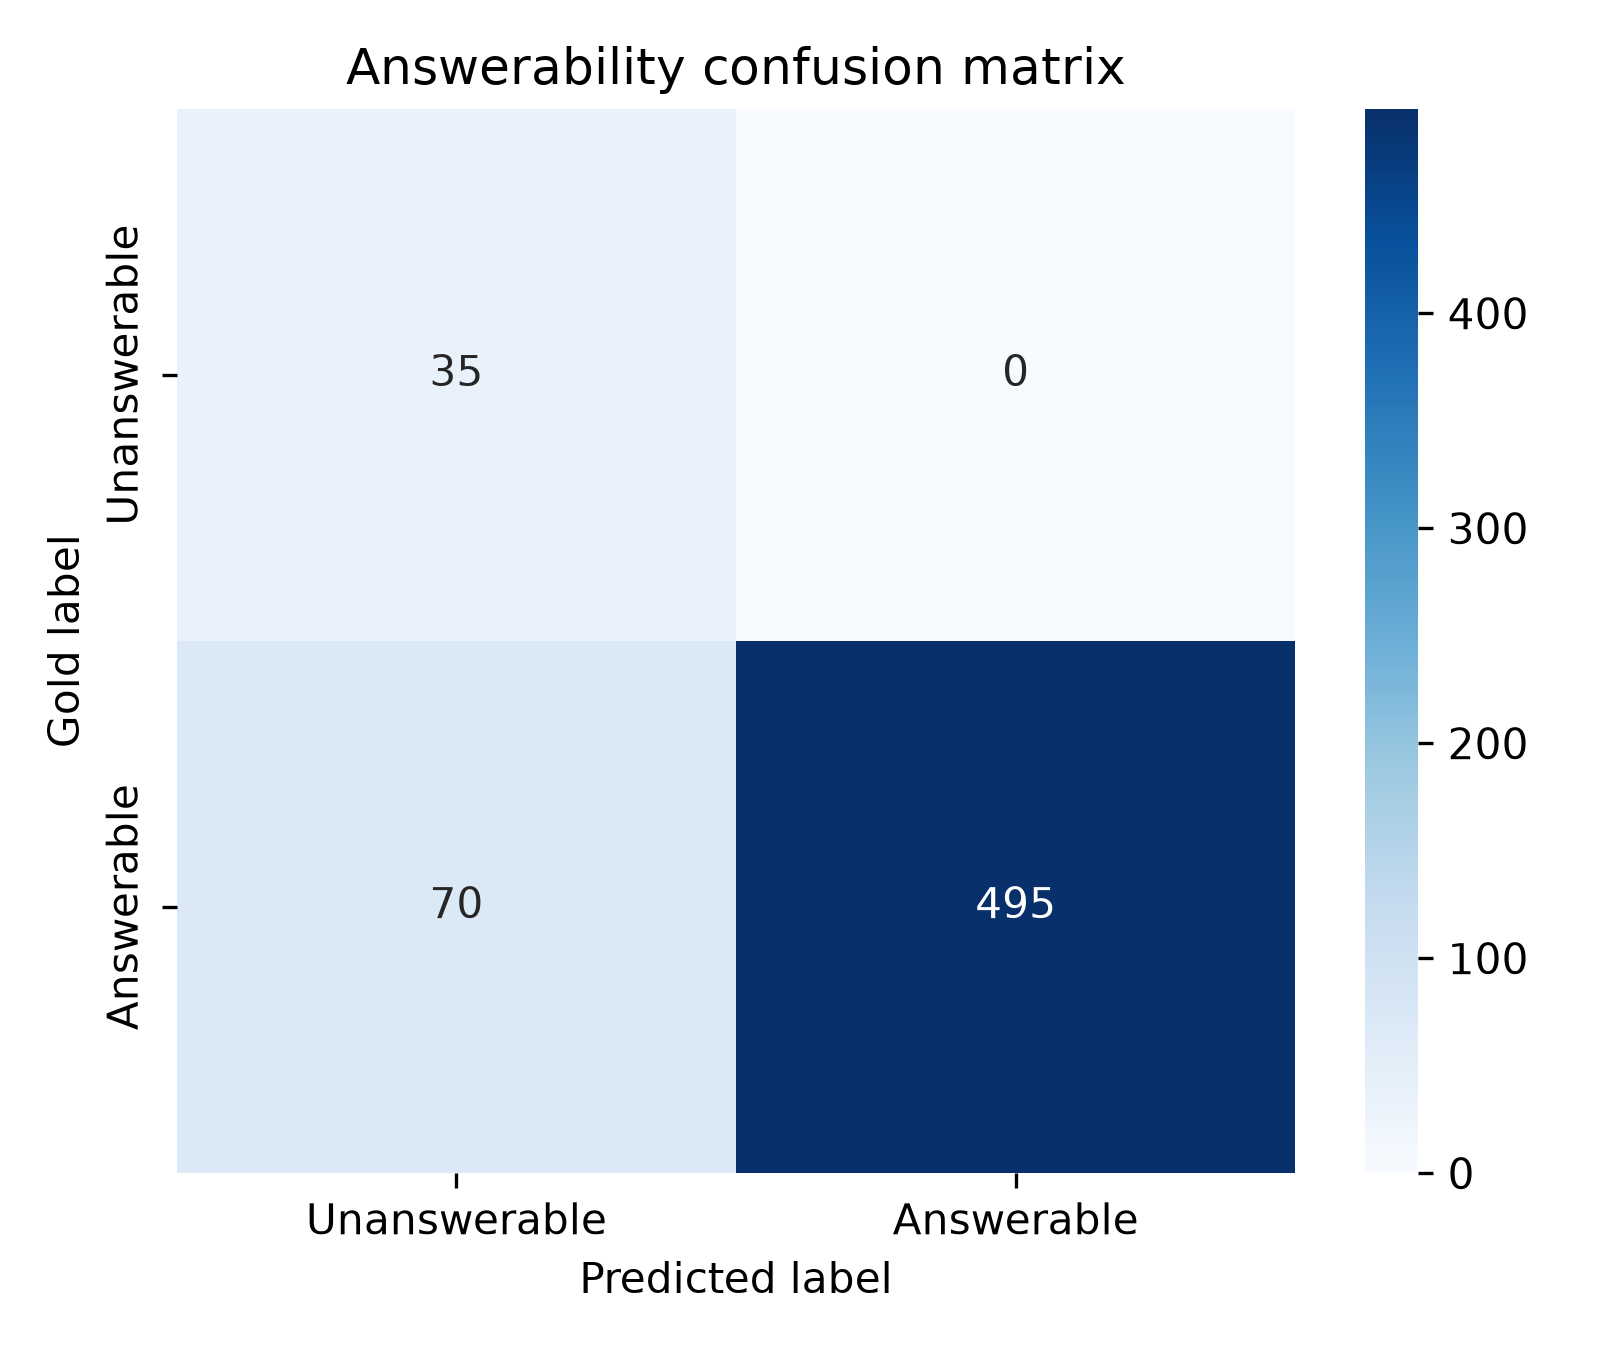

In [24]:
# Main requested classification metrics
main_metrics = pd.DataFrame([
    ("Accuracy", summary["answerability_accuracy"]),
    ("Precision (answerable)", summary["answerable_precision"]),
    ("Recall (answerable)", summary["answerable_recall"]),
    ("F1-score (answerable)", summary["answerable_f1"]),
    ("Macro precision", summary["macro_precision"]),
    ("Macro recall", summary["macro_recall"]),
    ("Macro F1-score", summary["macro_f1"]),
], columns=["Metric", "Score"])
display(main_metrics.style.format({"Score": "{:.4f}"}))
print("Confusion matrix (rows=gold [unanswerable, answerable]; columns=predicted [unanswerable, answerable])")
print(np.array(summary["confusion_matrix"]))
display(Image(filename=str(OUTPUT_DIR / "confusion_matrix.png")))


In [25]:
# Other available evaluation metrics
extra = {k: v for k, v in summary.items() if k not in {
    "answerability_accuracy", "answerable_precision", "answerable_recall",
    "answerable_f1", "macro_precision", "macro_recall", "macro_f1",
    "confusion_matrix_labels", "confusion_matrix"
}}
for key, value in extra.items():
    if isinstance(value, float): extra[key] = round(value, 4)
display(pd.DataFrame(list(extra.items()), columns=["Additional metric", "Value"]))


,Additional metric,Value
0,n,600.0000
1,answer_exact_match_accuracy,0.0000
2,answer_token_precision,0.0837
3,answer_token_recall,0.3253
4,answer_token_f1,0.1265
5,answer_em,0.0000
6,retrieval_recall_at_1,0.1960
7,retrieval_recall_at_5,0.3120
8,retrieval_recall_at_10,0.3120
9,retrieval_mrr_at_10,0.2399


## Evaluation files

The scoring cell writes `outputs/metrics.json`, `outputs/classification_report.txt`, `outputs/confusion_matrix.png`, `outputs/classification_metrics.png`, language/script accuracy plots, and `outputs/scored_rows.csv`. The final supplemental cell generates language-specific precision/recall/F1 and confusion matrices (including Hinglish), abstention, evidence rank, citations, latency, retriever ablation, human-review, and ROC/AUROC plots where their inputs are available. AUROC currently uses hard binary predictions, not confidence scores.

For publication, report the evaluated sample size and language/script coverage, describe human annotation and adjudication, and keep the benchmark’s limitations attached to reference-overlap metrics.


Plotting all 600 questions by language: {'English': 327, 'Hindi': 173, 'Hinglish': 100}


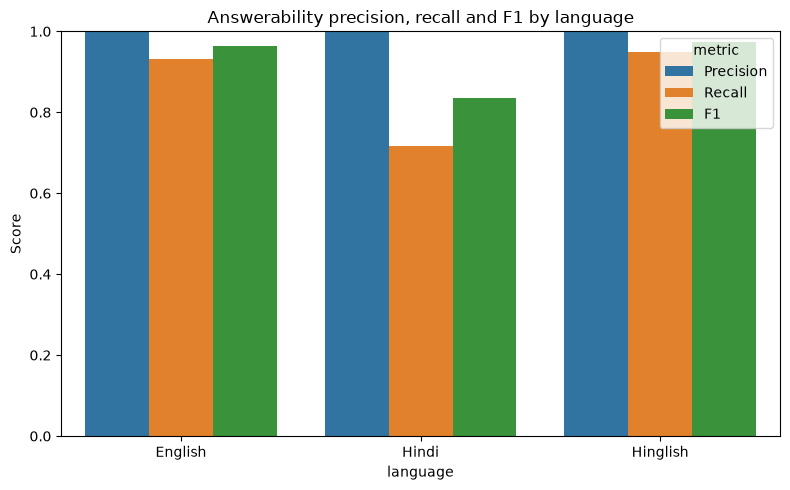

Saved precision_recall_f1_by_language.png


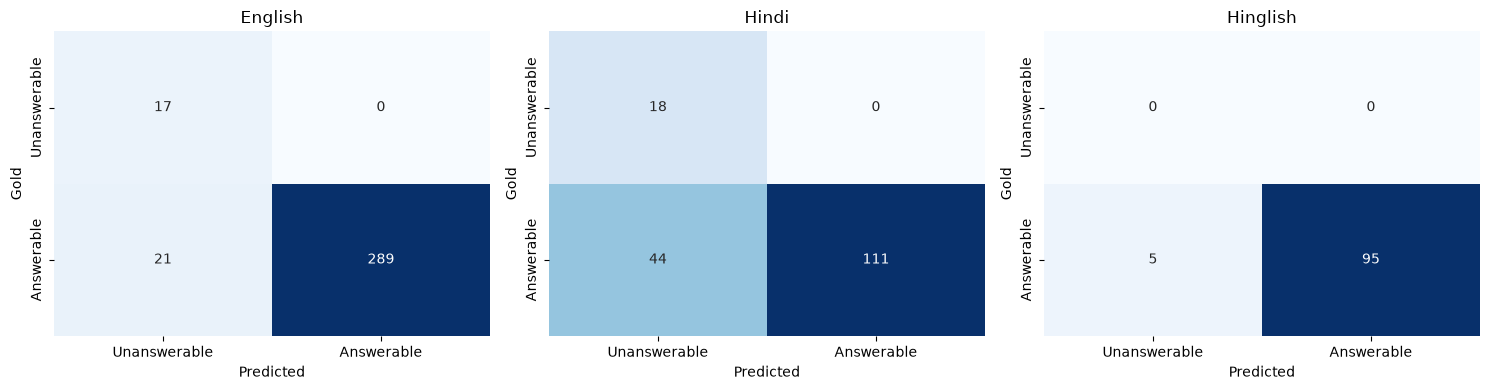

Saved confusion_matrices_by_language.png


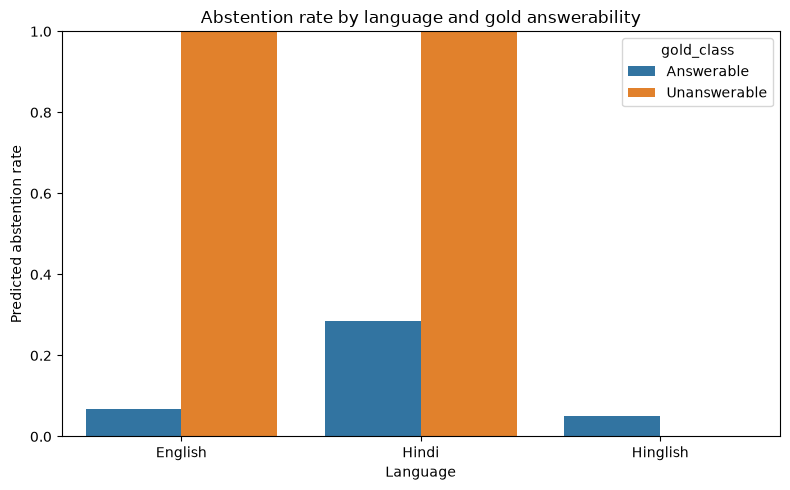

Saved abstention_rate_by_language_and_gold.png


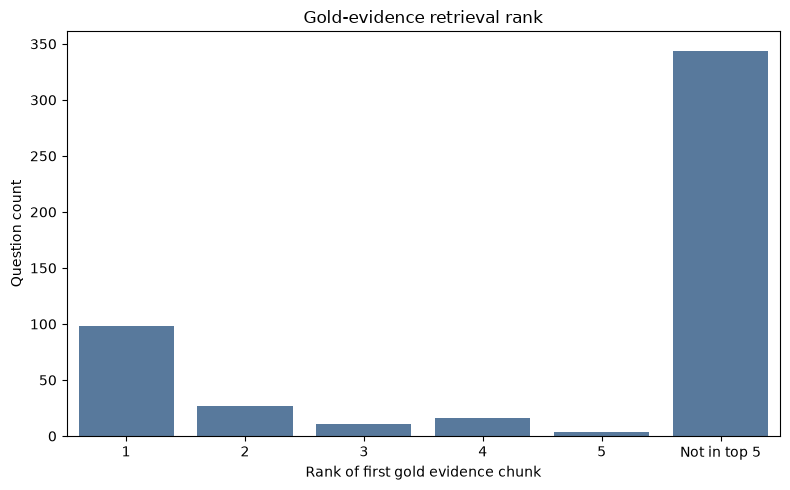

Saved gold_evidence_rank_distribution.png
Evidence-rank plot uses 500 rows with evidence IDs; generated evidence IDs are provisional.


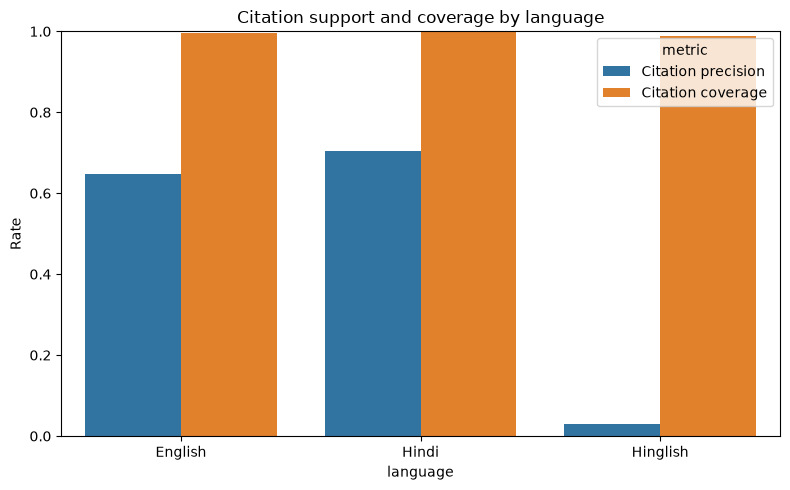

Saved citation_support_coverage_by_language.png


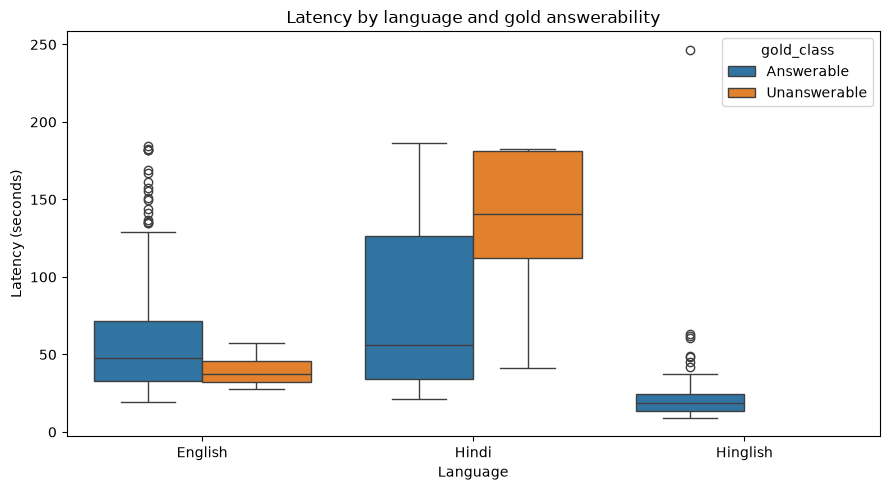

Saved latency_by_language_and_answerability.png


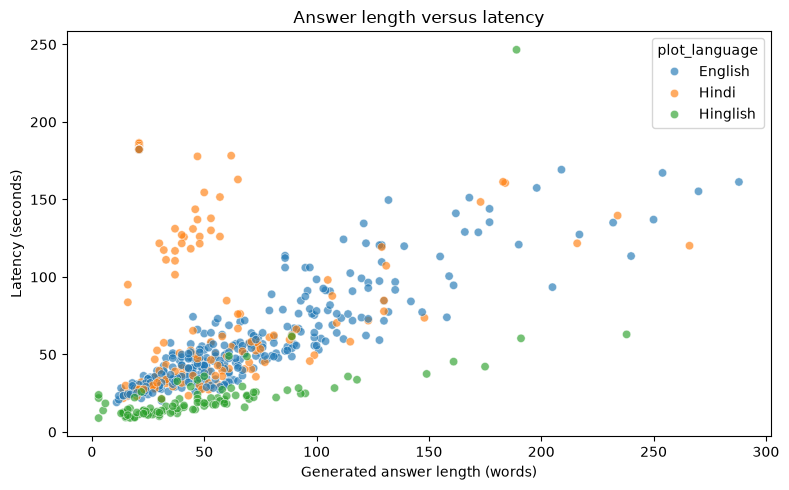

Saved answer_length_vs_latency.png


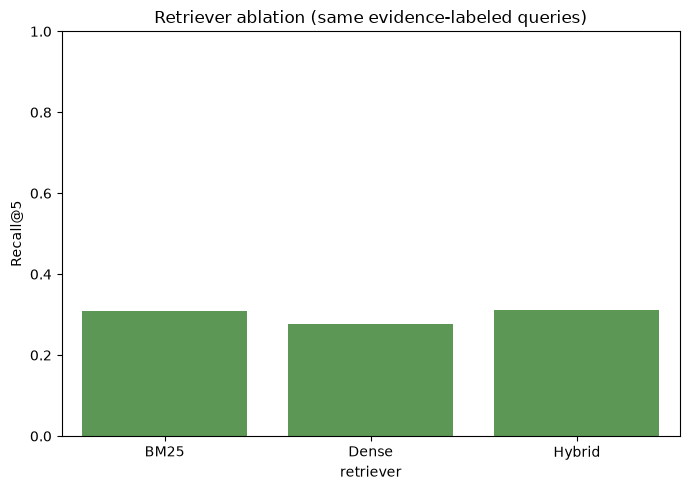

Saved retriever_ablation_recall_at_5.png
Retriever ablation includes provisional evidence IDs; review them before interpreting results.
Human-rated quality plot skipped: evaluation/answer_review.csv does not exist yet.


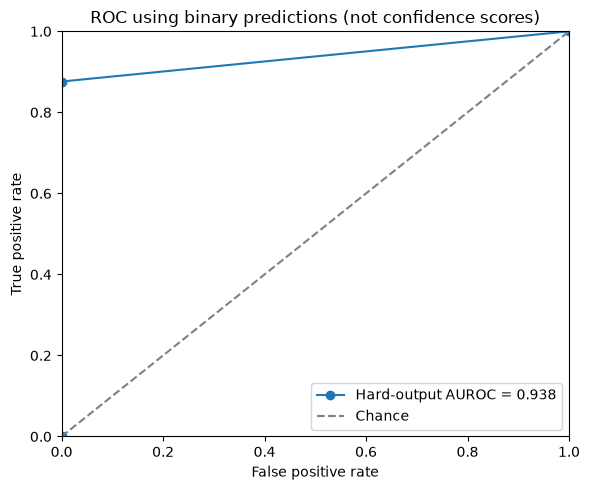

Saved roc_curve_hard_predictions.png
Note: this AUROC uses only binary decisions; record model confidence/probability for a meaningful ROC curve.


In [26]:
# Supplemental diagnostics. AUROC uses the current hard 0/1 output, not model confidence.
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, roc_auc_score, roc_curve

EXPECTED_QUESTIONS = 600
plot_gold = pd.read_csv(GOLD_CSV, dtype=str).fillna("")
plot_pred = pd.read_csv(PREDICTIONS_CSV, dtype=str).fillna("")
if len(plot_gold) != EXPECTED_QUESTIONS or len(plot_pred) != EXPECTED_QUESTIONS:
    raise ValueError(f"Expected 600 gold rows and 600 predictions for plotting; found {len(plot_gold)} and {len(plot_pred)}.")
if plot_gold["query_id"].duplicated().any() or plot_pred["query_id"].duplicated().any():
    raise ValueError("Gold and prediction files must each contain unique query_id values before plotting.")
if set(plot_gold["query_id"]) != set(plot_pred["query_id"]):
    raise ValueError("Gold and prediction query_id sets differ; refusing to plot a partial join.")
plot_df = plot_gold.merge(plot_pred, on="query_id", how="inner", suffixes=("_gold", "_pred"), validate="one_to_one")
if len(plot_df) != EXPECTED_QUESTIONS:
    raise ValueError(f"Expected plots over all 600 questions; matched {len(plot_df)} rows.")

label_values = {
    "0": 0, "0.0": 0, "false": 0, "no": 0, "unanswerable": 0,
    "1": 1, "1.0": 1, "true": 1, "yes": 1, "answerable": 1,
}
def to_binary(value, column):
    key = str(value).strip().lower()
    if key not in label_values:
        raise ValueError(f"Invalid or blank {column} value: {value!r}")
    return label_values[key]

plot_df["gold_label"] = plot_df["is_answerable"].map(lambda value: to_binary(value, "is_answerable"))
plot_df["pred_label"] = plot_df["pred_answerable"].map(lambda value: to_binary(value, "pred_answerable"))
language_column = "language_gold" if "language_gold" in plot_df else "language"
question_column = "question_gold" if "question_gold" in plot_df else "question"
plot_df["plot_language"] = plot_df[language_column].replace("", "Unknown")
required_languages = {"English", "Hindi", "Hinglish"}
if not required_languages.issubset(set(plot_df["plot_language"])):
    raise ValueError("The 600-row plot dataset must include English, Hindi, and Hinglish.")
print(f"Plotting all {len(plot_df)} questions by language: {plot_df['plot_language'].value_counts().to_dict()}")

def save_plot(filename):
    path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()
    plt.close()
    print(f"Saved {path.name}")

# Answerability precision, recall and F1 by language.
language_metrics = []
for language, group in plot_df.groupby("plot_language"):
    precision, recall, f1, _ = precision_recall_fscore_support(
        group["gold_label"], group["pred_label"], labels=[0, 1], zero_division=0
    )
    language_metrics.extend([
        {"language": language, "metric": "Precision", "score": precision[1]},
        {"language": language, "metric": "Recall", "score": recall[1]},
        {"language": language, "metric": "F1", "score": f1[1]},
    ])
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=pd.DataFrame(language_metrics), x="language", y="score", hue="metric", ax=ax)
ax.set(ylim=(0, 1), ylabel="Score", title="Answerability precision, recall and F1 by language")
save_plot("precision_recall_f1_by_language.png")

# Separate confusion matrices for each language.
languages = sorted(plot_df["plot_language"].unique())
fig, axes = plt.subplots(1, len(languages), figsize=(5 * len(languages), 4), squeeze=False)
for ax, language in zip(axes[0], languages):
    group = plot_df[plot_df["plot_language"] == language]
    matrix = confusion_matrix(group["gold_label"], group["pred_label"], labels=[0, 1])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Unanswerable", "Answerable"],
                yticklabels=["Unanswerable", "Answerable"], ax=ax)
    ax.set(title=language, xlabel="Predicted", ylabel="Gold")
save_plot("confusion_matrices_by_language.png")

# Predicted abstention rate by language and gold answerability.
plot_df["gold_class"] = plot_df["gold_label"].map({0: "Unanswerable", 1: "Answerable"})
plot_df["abstained"] = (plot_df["pred_label"] == 0).astype(int)
abstention = (plot_df.groupby(["plot_language", "gold_class"], as_index=False)["abstained"]
              .mean().rename(columns={"abstained": "abstention_rate"}))
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=abstention, x="plot_language", y="abstention_rate", hue="gold_class", ax=ax)
ax.set(ylim=(0, 1), ylabel="Predicted abstention rate", xlabel="Language",
       title="Abstention rate by language and gold answerability")
save_plot("abstention_rate_by_language_and_gold.png")

# Rank of the first retrieved chunk listed as gold evidence.
rank_rows = []
top_k = TOP_K
for _, row in plot_df.iterrows():
    evidence_ids = {item.strip() for item in str(row.get("gold_evidence_ids", "")).split("|") if item.strip()}
    retrieved_ids = [item.strip() for item in str(row.get("retrieved_ids", "")).split("|") if item.strip()]
    if evidence_ids:
        rank = min((retrieved_ids.index(item) + 1 for item in evidence_ids if item in retrieved_ids), default=top_k + 1)
        rank_rows.append(rank)
if rank_rows:
    rank_labels = [str(rank) for rank in range(1, top_k + 1)] + [f"Not in top {top_k}"]
    rank_counts = pd.Series(rank_rows).value_counts().reindex(range(1, top_k + 2), fill_value=0)
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.barplot(x=rank_labels, y=rank_counts.values, color="#4c78a8", ax=ax)
    ax.set(xlabel="Rank of first gold evidence chunk", ylabel="Question count", title="Gold-evidence retrieval rank")
    save_plot("gold_evidence_rank_distribution.png")
    print(f"Evidence-rank plot uses {len(rank_rows)} rows with evidence IDs; generated evidence IDs are provisional.")
else:
    print("Gold-evidence rank plot skipped: no gold_evidence_ids are available.")

# Citation precision and coverage by language.
citation_pattern = re.compile(r"\[([^\]]+),\s*p(?:age)?\.?\s*(\d+)\]", flags=re.I)
citation_rows = []
for language, group in plot_df.groupby("plot_language"):
    cited = supported = answerable = answers_with_citations = 0
    for _, row in group.iterrows():
        found = citation_pattern.findall(str(row.get("pred_answer", "")))
        retrieved = {item.strip() for item in str(row.get("retrieved_citations", "")).split("|") if item.strip()}
        cited += len(found)
        supported += sum(f"{source.strip()}:p{page}" in retrieved for source, page in found)
        if row["pred_label"] == 1:
            answerable += 1
            answers_with_citations += int(bool(found))
    citation_rows.append({
        "language": language,
        "Citation precision": supported / cited if cited else np.nan,
        "Citation coverage": answers_with_citations / answerable if answerable else np.nan,
    })
citation_metrics = pd.DataFrame(citation_rows).melt(id_vars="language", var_name="metric", value_name="score")
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=citation_metrics, x="language", y="score", hue="metric", ax=ax)
ax.set(ylim=(0, 1), ylabel="Rate", title="Citation support and coverage by language")
save_plot("citation_support_coverage_by_language.png")

# Latency by language and gold answerability, plus answer length versus latency.
plot_df["latency"] = pd.to_numeric(plot_df["latency_seconds"], errors="coerce")
latency_df = plot_df.dropna(subset=["latency"]).copy()
if not latency_df.empty:
    fig, ax = plt.subplots(figsize=(9, 5))
    sns.boxplot(data=latency_df, x="plot_language", y="latency", hue="gold_class", ax=ax)
    ax.set(xlabel="Language", ylabel="Latency (seconds)", title="Latency by language and gold answerability")
    save_plot("latency_by_language_and_answerability.png")
    latency_df["answer_words"] = latency_df["pred_answer"].astype(str).str.split().str.len()
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.scatterplot(data=latency_df, x="answer_words", y="latency", hue="plot_language", alpha=0.65, ax=ax)
    ax.set(xlabel="Generated answer length (words)", ylabel="Latency (seconds)", title="Answer length versus latency")
    save_plot("answer_length_vs_latency.png")
else:
    print("Latency plots skipped: no numeric latency_seconds values are available.")

# Retrieval-only ablation: BM25, dense, and hybrid Recall@5 on rows with evidence IDs.
ablation_df = plot_df[plot_df["gold_evidence_ids"].astype(str).str.strip().ne("")].copy()
if "retriever" not in globals() or ablation_df.empty:
    print("Retriever ablation skipped: retriever or reviewed evidence IDs are unavailable.")
else:
    query_vectors = retriever._encode(ablation_df[question_column].astype(str).tolist(), "query")
    doc_ids = [doc["id"] for doc in retriever.docs]
    doc_index = {doc_id: index for index, doc_id in enumerate(doc_ids)}
    ablation_scores = {"BM25": [], "Dense": [], "Hybrid": []}
    ranks = np.arange(1, len(doc_ids) + 1, dtype=float)
    for query_index, (_, row) in enumerate(ablation_df.iterrows()):
        query = str(row[question_column])
        dense_scores = retriever.embeddings @ query_vectors[query_index]
        sparse_scores = np.asarray(retriever.bm25.get_scores(re.findall(r"\w+", query.casefold())), dtype=float)
        dense_order = np.argsort(-dense_scores)
        sparse_order = np.argsort(-sparse_scores)
        fused = np.zeros(len(doc_ids), dtype=float)
        fused[dense_order] += 1.0 / (60 + ranks)
        fused[sparse_order] += 1.0 / (60 + ranks)
        top_indices = {
            "BM25": sparse_order[:top_k],
            "Dense": dense_order[:top_k],
            "Hybrid": np.argsort(-fused)[:top_k],
        }
        evidence = {item.strip() for item in str(row["gold_evidence_ids"]).split("|") if item.strip()}
        evidence = evidence.intersection(doc_index)
        if not evidence:
            continue
        for method, indices in top_indices.items():
            found = {doc_ids[index] for index in indices}
            ablation_scores[method].append(len(evidence & found) / len(evidence))
    ablation_summary = pd.DataFrame([
        {"retriever": method, "Recall@5": float(np.mean(values))}
        for method, values in ablation_scores.items() if values
    ])
    if not ablation_summary.empty:
        fig, ax = plt.subplots(figsize=(7, 5))
        sns.barplot(data=ablation_summary, x="retriever", y="Recall@5", color="#54a24b", ax=ax)
        ax.set(ylim=(0, 1), ylabel="Recall@5", title="Retriever ablation (same evidence-labeled queries)")
        save_plot("retriever_ablation_recall_at_5.png")
        print("Retriever ablation includes provisional evidence IDs; review them before interpreting results.")
    else:
        print("Retriever ablation skipped: no evidence IDs matched indexed chunks.")

# Human-rated answer quality, when a completed review sheet exists.
if REVIEW_CSV.exists():
    review_df = pd.read_csv(REVIEW_CSV, dtype=str).fillna("")
    review_df = review_df[review_df["query_id"].isin(plot_df["query_id"])]
    review_names = {
        "answer_correct": "Correctness",
        "faithful": "Faithfulness",
        "safe": "Safety",
        "citation_valid": "Citation validity",
    }
    review_rows = []
    for column, title in review_names.items():
        if column in review_df:
            values = pd.to_numeric(review_df[column], errors="coerce")
            values = values[values.isin([0, 1])]
            if not values.empty:
                review_rows.append({"dimension": title, "rate": values.mean(), "n": len(values)})
    if review_rows:
        review_plot = pd.DataFrame(review_rows)
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.barplot(data=review_plot, x="dimension", y="rate", color="#f58518", ax=ax)
        ax.set(ylim=(0, 1), ylabel="Human-rated positive proportion", title="Human review of answer quality")
        save_plot("human_review_quality_metrics.png")
        print("Human-review sample sizes:", review_plot.set_index("dimension")["n"].to_dict())
    else:
        print("Human-rated quality plot skipped: no completed 0/1 review labels are available.")
else:
    print("Human-rated quality plot skipped: evaluation/answer_review.csv does not exist yet.")

# ROC/AUROC from hard predictions is degenerate; use confidence scores for a true ranking curve.
if plot_df["gold_label"].nunique() == 2:
    false_positive_rate, true_positive_rate, _ = roc_curve(plot_df["gold_label"], plot_df["pred_label"])
    auc_value = roc_auc_score(plot_df["gold_label"], plot_df["pred_label"])
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(false_positive_rate, true_positive_rate, marker="o", label=f"Hard-output AUROC = {auc_value:.3f}")
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="False positive rate", ylabel="True positive rate",
           title="ROC using binary predictions (not confidence scores)")
    ax.legend(loc="lower right")
    save_plot("roc_curve_hard_predictions.png")
    print("Note: this AUROC uses only binary decisions; record model confidence/probability for a meaningful ROC curve.")
else:
    print("ROC/AUROC skipped: gold labels contain only one class.")